# A super-Earth with the power-2 law: accuracy, cost, a fit, and a proven light curve

The power-2 law $I(\mu) = 1 - c\,(1 - \mu^\alpha)$ matches model stellar atmospheres better than the
quadratic law (Maxted 2018). It has no elliptic-integral solution, so most codes integrate it numerically.
batman's numerical integrator works to a requested tolerance (`max_err`, default 1 ppm); pizzetti uses the
interior series with a **proven** bound (default 1e-9) and power series about the contacts (~1e-15).

This notebook uses a Kepler-like data set (30 transits at 1-min cadence, $R_p/R_\star = 0.02$) to show

1. the model error of both codes along a transit,
2. the cost of one likelihood evaluation, also for batman at a tighter tolerance,
3. a maximum-likelihood fit and a short emcee run with both codes,
4. a light curve whose error bound is proven for every sample (`limb="proven"`).

Run time: about two minutes.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import emcee

import batman
import pizzetti

truth = dict(t0=0.0, per=10.0, rp=0.02, a=20.0, b=0.2, c=0.6, alpha=0.6)
sigma = 150e-6
epochs = np.arange(30)
t_one = np.arange(-0.12, 0.12, 1.0 / 1440)
t = (truth["t0"] + epochs[:, None] * truth["per"] + t_one[None, :]).ravel()

def params(module, t0, per, rp, a, b, c, alpha):
    p = module.TransitParams()
    p.t0, p.per, p.rp, p.a = t0, per, rp, a
    p.inc = np.degrees(np.arccos(b / a))
    p.ecc, p.w = 0.0, 90.0
    p.limb_dark, p.u = "power2", [c, alpha]
    return p

p_true = params(pizzetti, **truth)
reference = pizzetti.TransitModel(p_true, t, series_tol=0.0, limb="quadrature")   # ~1e-16
f_true = reference.light_curve(p_true)
y = f_true + sigma * np.random.default_rng(7).standard_normal(t.size)
print(t.size, "samples,", np.sum(reference.ds < 1 + truth["rp"]), "in transit")

10380 samples, 6870 in transit


## 1. Model error along one transit

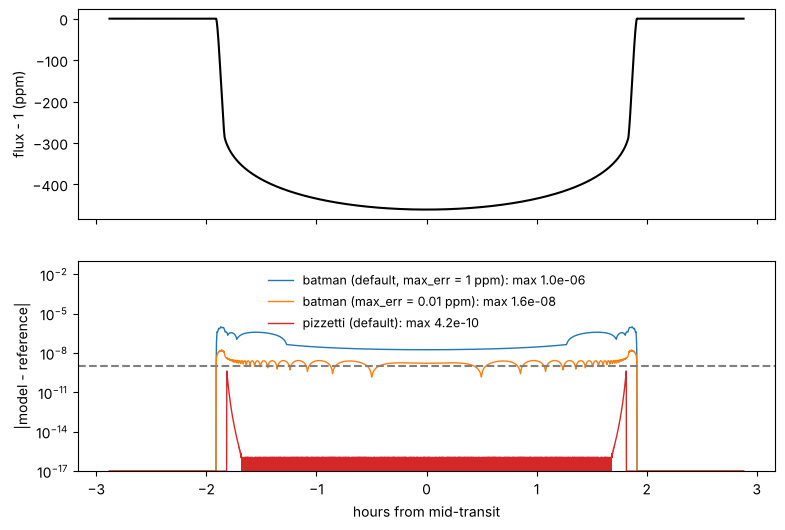

In [2]:
t1 = np.linspace(-0.12, 0.12, 4001)
ref1 = pizzetti.TransitModel(p_true, t1, series_tol=0.0, limb="quadrature").light_curve(p_true)
curves = {
    "batman (default, max_err = 1 ppm)": batman.TransitModel(params(batman, **truth), t1),
    "batman (max_err = 0.01 ppm)": batman.TransitModel(params(batman, **truth), t1, max_err=0.01),
    "pizzetti (default)": pizzetti.TransitModel(p_true, t1),
}
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(24 * t1, 1e6 * (ref1 - 1), "k")
ax[0].set_ylabel("flux - 1 (ppm)")
for (name, m), col in zip(curves.items(), ("C0", "C1", "C3")):
    e = np.abs(m.light_curve(params(batman if "batman" in name else pizzetti, **truth)) - ref1)
    ax[1].semilogy(24 * t1, np.maximum(e, 1e-17), color=col, lw=1, label=f"{name}: max {e.max():.1e}")
ax[1].axhline(1e-9, ls="--", color="0.5")
ax[1].set_ylim(1e-17, 1e-1)
ax[1].set_xlabel("hours from mid-transit"); ax[1].set_ylabel("|model - reference|")
ax[1].legend(fontsize=9, loc="upper center", ncol=1, frameon=False);

## 2. Cost of one likelihood evaluation

Each call changes the parameters (as in a fit), so the orbit is recomputed every time.

In [3]:
def make_log_prob(module, **kw):
    prm = params(module, **truth)
    model = module.TransitModel(prm, t, **kw)
    def log_prob(th):
        t0, per, rp, a, b, c, alpha = th
        b = abs(b)                        # the light curve depends on |b|
        if not (0 < rp < 0.5 and 1.5 < a < 100 and b < 1 + rp and 0 < c < 1 and 0 < alpha < 2):
            return -np.inf
        prm.t0, prm.per, prm.rp, prm.a = t0, per, rp, a
        prm.inc = np.degrees(np.arccos(b / a))
        prm.u = [c, alpha]
        r = y - model.light_curve(prm)
        return -0.5 * np.dot(r, r) / sigma**2
    return log_prob

th0 = np.array([truth[k] for k in ("t0", "per", "rp", "a", "b", "c", "alpha")])
draws = th0 + np.array([1e-4, 1e-6, 2e-4, 0.3, 0.1, 0.1, 0.1]) * np.random.default_rng(3).standard_normal((100, 7))
draws[:, 4] = np.abs(draws[:, 4])
for name, lp in (("batman", make_log_prob(batman)), ("batman, max_err=0.01", make_log_prob(batman, max_err=0.01)),
                 ("pizzetti", make_log_prob(pizzetti))):
    lp(th0)
    s = time.perf_counter()
    for th in draws:
        lp(th)
    print(f"{name:22s} {1e3 * (time.perf_counter() - s) / len(draws):6.2f} ms per evaluation")

batman                   1.00 ms per evaluation


batman, max_err=0.01     5.11 ms per evaluation
pizzetti                 0.58 ms per evaluation


## 3. Maximum likelihood and a short MCMC run

Both codes find the same maximum. The short emcee runs (identical proposals) agree within their Monte Carlo
noise; the 20 000-step runs of the paper are in `inference/`.

In [4]:
# optimise in units of a typical scale per parameter: Powell, then Nelder-Mead to polish
scale = np.array([1e-4, 1e-6, 1e-4, 0.3, 0.1, 0.1, 0.1])
start = th0 + np.array([3e-4, 2e-6, 5e-4, -0.4, 0.1, -0.1, 0.15])
fits = {}
for name, module in (("batman", batman), ("pizzetti", pizzetti)):
    lp = make_log_prob(module)
    nll = lambda x: -lp(th0 + x * scale)
    s = time.perf_counter()
    res = minimize(nll, (start - th0) / scale, method="Powell", options=dict(xtol=1e-6, ftol=1e-10, maxfev=20000))
    res = minimize(nll, res.x, method="Nelder-Mead", options=dict(xatol=1e-7, fatol=1e-9, maxfev=20000, adaptive=True))
    fits[name] = th0 + res.x * scale
    fits[name][4] = abs(fits[name][4])
    print(f"{name:9s} -lnL = {res.fun:.4f}  ({res.nfev} evaluations in the polish, {time.perf_counter() - s:.1f} s)")
print("difference of the two maxima, in units of the scale:")
print(np.round((fits["pizzetti"] - fits["batman"]) / scale, 3))

batman    -lnL = 5130.2140  (788 evaluations in the polish, 9.3 s)


pizzetti  -lnL = 5130.1785  (967 evaluations in the polish, 5.0 s)
difference of the two maxima, in units of the scale:
[-0.011  0.059  0.035 -0.005  0.     0.003 -0.023]


batman     21.7 s


pizzetti   13.0 s


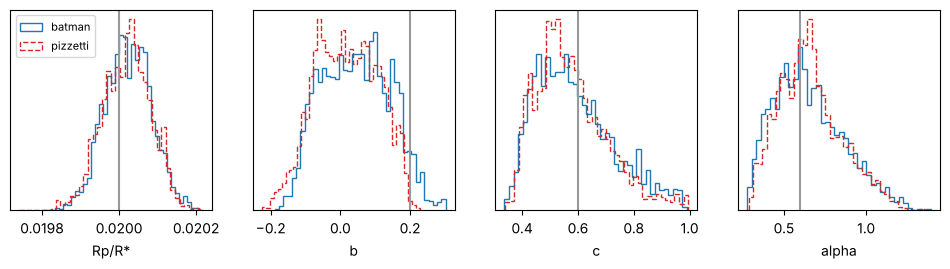

In [5]:
nwalkers, nsteps = 32, 800
p0 = fits["pizzetti"] + np.array([1e-4, 1e-6, 1e-4, 0.05, 0.02, 0.02, 0.02]) * np.random.default_rng(1).standard_normal((nwalkers, 7))
p0[:, 4] = np.abs(p0[:, 4])
chains = {}
for name, module in (("batman", batman), ("pizzetti", pizzetti)):
    sampler = emcee.EnsembleSampler(nwalkers, 7, make_log_prob(module))
    sampler.random_state = np.random.RandomState(5).get_state()
    s = time.perf_counter()
    sampler.run_mcmc(p0, nsteps, progress=False)
    chains[name] = sampler.get_chain(discard=300, flat=True)
    print(f"{name:9s} {time.perf_counter() - s:5.1f} s")
labels = ["t0", "P", "Rp/R*", "a/R*", "b", "c", "alpha"]
fig, axs = plt.subplots(1, 4, figsize=(12, 2.6))
for ax, i in zip(axs, (2, 4, 5, 6)):
    for name, col, ls in (("batman", "C0", "-"), ("pizzetti", "C3", "--")):
        ax.hist(chains[name][:, i], bins=40, histtype="step", color=col, ls=ls, density=True, label=name)
    ax.axvline(th0[i], color="0.6")
    ax.set_xlabel(labels[i]); ax.set_yticks([])
axs[0].legend(fontsize=8);

## 4. A light curve with a proven error bound

With `limb="proven"` the limb part is also computed from pieces with a proven error bound, and
`return_certified=True` reports for every sample whether its flux error is proven to be below `series_tol`
(the interior series, the proven limb pieces and the out-of-transit samples). The set-up is paid once per
light curve.

In [6]:
z = reference.ds
for tol in (1e-9, 1e-12):
    s = time.perf_counter()
    f, cert = pizzetti.occult(z, truth["rp"], [truth["c"], truth["alpha"]], "power2", series_tol=tol,
                              limb="proven", return_certified=True)
    dt = time.perf_counter() - s
    err = np.max(np.abs(f - f_true))
    print(f"series_tol = {tol:.0e}: {cert.mean():.1%} of the samples certified, largest error {err:.1e}, {1e3 * dt:.1f} ms")

series_tol = 1e-09: 100.0% of the samples certified, largest error 3.4e-10, 8.9 ms
series_tol = 1e-12: 100.0% of the samples certified, largest error 3.5e-13, 15.0 ms
